#  Sentiment Analysis on Social Media Posts

This project uses Natural Language Processing (NLP) and Machine Learning to analyze and classify the sentiment of social media posts into three categories: **positive**, **negative**, and **neutral**.

The model is trained on a dataset of real-world posts that include text content and labeled sentiments. After preprocessing and cleaning the text, the model is able to learn from the data and predict the sentiment of new, unseen inputs.


###  Importing Required Libraries


In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


### Loading the Dataset

Here, we load the sentiment analysis dataset using `pandas.read_csv()`.

The dataset contains social media posts (such as tweets) along with their associated sentiment labels (positive, negative, or neutral).


In [62]:
# Load the dataset (CSV file) into a pandas DataFrame
df = pd.read_csv("/kaggle/input/sentiment-analysis55/sentiment_analysis (1).csv")

In [63]:
# Display the first 5 rows to understand the structure of the dataset
df.head()

,Year,Month,Day,Time of Tweet,text,sentiment,Platform
0,2018,8,18,morning,What a great day!!! Looks like dream.,positive,Twitter
1,2018,8,18,noon,"I feel sorry, I miss you here in the sea beach",positive,Facebook
2,2017,8,18,night,Don't angry me,negative,Facebook
3,2022,6,8,morning,We attend in the class just for listening teac...,negative,Facebook
4,2022,6,8,noon,"Those who want to go, let them go",negative,Instagram


In [64]:
# Print the column names to identify which column contains the text and which contains the sentiment labels
df.columns

Index(['Year', 'Month', 'Day', 'Time of Tweet', 'text', 'sentiment',
       'Platform'],
      dtype='object')

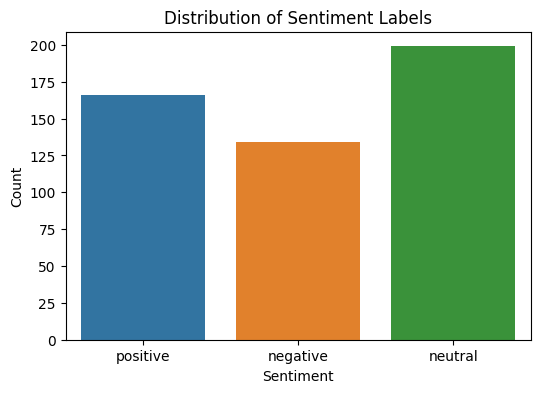

In [65]:
# Visualize how many samples exist for each sentiment category
plt.figure(figsize=(6,4))
sns.countplot(x='sentiment', data=df)
plt.title("Distribution of Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()


###  Output Explanation:

The bar chart shows that:
- **Neutral** posts are the most frequent (around 200),
- Followed by **positive** posts (~170),
- And **negative** posts are the fewest (~135).

This means the dataset is slightly imbalanced, with more neutral posts. This is important to consider during model training to avoid biased predictions.


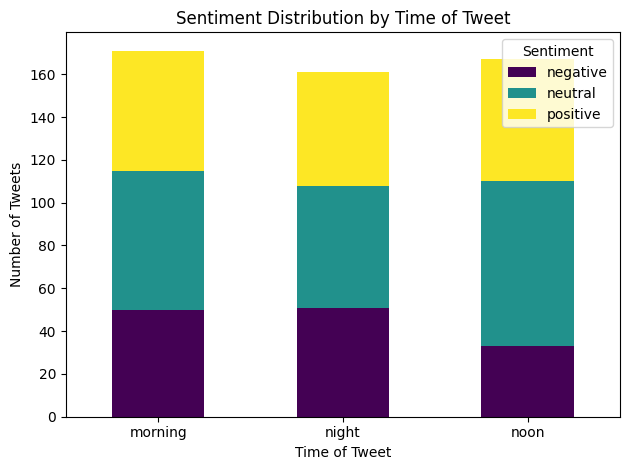

In [80]:
import pandas as pd
import matplotlib.pyplot as plt

# Sentiment count by Time of Tweet
sentiment_time = df.groupby(['Time of Tweet', 'sentiment']).size().unstack(fill_value=0)

sentiment_time.plot(kind='bar', stacked=True, colormap='viridis')
plt.title('Sentiment Distribution by Time of Tweet')
plt.xlabel('Time of Tweet')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()


- People tend to post more positively in the morning and around noon—possibly due to being well-rested or energized.

- Slightly more negativity appears at night, which may reflect fatigue, stress, or reflection on the day.

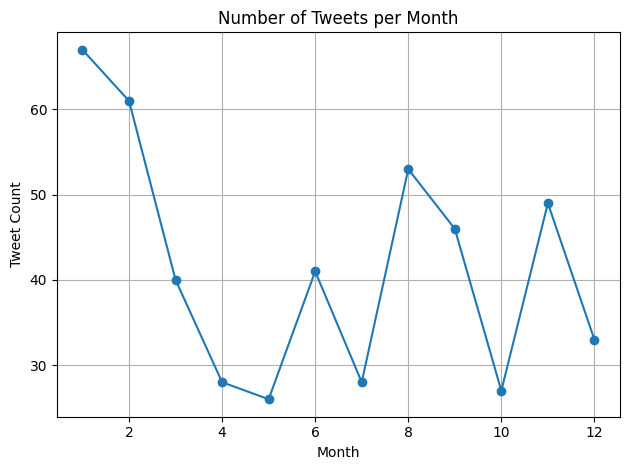

In [79]:

# Tweet counts per Month
monthly_counts = df.groupby('Month').size()

monthly_counts.plot(kind='line', marker='o')
plt.title('Number of Tweets per Month')
plt.xlabel('Month')
plt.ylabel('Tweet Count')
plt.grid(True)
plt.tight_layout()
plt.show()

- The start of the year (January–February) sees high tweet activity—possibly due to New Year reflections or resolutions.

- Mid-year (spring) shows a decline, which could be due to academic or work-related busyness.

### Downloading NLTK Resources

In this step, we download the required NLTK resources needed for text preprocessing.

In [67]:
# Download required NLTK resources
import nltk
nltk.download('punkt', force=True)      # For tokenizing words
nltk.download('stopwords')              # For removing common stopwords
nltk.download('wordnet')                # For lemmatization (if needed)
nltk.download('punkt_tab') # Download the 'punkt_tab' resource

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [68]:
# Import essential text cleaning tools
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import string


### Text Cleaning Function

In this step, we define a custom function `clean_text()` that performs multiple preprocessing tasks on the raw text:

- Converts all text to lowercase.
- Removes URLs, mentions (@user), hashtags, and punctuation using regular expressions.
- Tokenizes the text into individual words.
- Removes stopwords like "the", "is", "in", etc.
- Lemmatizes the words to their base form (e.g., "running" → "run").

This process helps reduce noise in the data and improves model accuracy by focusing only on meaningful words.


In [69]:
import re
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))


# Text cleaning function
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)      # Remove URLs
    text = re.sub(r"@\w+", "", text)         # Remove @mentions
    text = re.sub(r"#\w+", "", text)         # Remove hashtags
    text = re.sub(r"[^\w\s]", "", text)      # Remove punctuation

    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words and word.isalpha()]  # Remove stopwords & non-alpha
    lemmatized = [lemmatizer.lemmatize(token) for token in tokens]
    return " ".join(lemmatized)



### Applying Text Cleaning to the Dataset

Here, we apply the `clean_text()` function to every row in the `'text'` column using `.apply()`.

We create a new column called `'cleaned_text'` that contains the processed version of the original text.

To verify the changes, we display both the original and cleaned text side by side. This helps us see how unnecessary words, symbols, and noise have been removed.

Example:
- Original: `What a great day!!! Looks like dream.`
- Cleaned: `great day look like dream`


In [70]:
# Apply the clean_text function to all rows in the 'text' column
df['cleaned_text'] = df['text'].apply(clean_text)

# Show original vs cleaned
df[['text', 'cleaned_text']].head()


,text,cleaned_text
0,What a great day!!! Looks like dream.,great day look like dream
1,"I feel sorry, I miss you here in the sea beach",feel sorry miss sea beach
2,Don't angry me,dont angry
3,We attend in the class just for listening teac...,attend class listening teacher reading slide n...
4,"Those who want to go, let them go",want go let go


###  Vectorization and Model Training (TF-IDF + SVM)

In this step, we perform two main tasks:

### 1. Text Vectorization:
We use `TfidfVectorizer` to convert the cleaned text into numerical features that a machine learning model can understand.
- `ngram_range=(1,2)` means we include both unigrams and bigrams.
- `min_df=2` ignores terms that appear in fewer than 2 documents.

### 2. Splitting the Data:
We split the data into training and testing sets using `train_test_split`, with 80% for training and 20% for testing.

### 3. Model Building and Training:
We use a `LinearSVC` classifier (Support Vector Machine with a linear kernel) for sentiment classification.
- `C=1.5`: Controls the regularization strength.
- `class_weight='balanced'`: Adjusts for class imbalance automatically.

Finally, we train the model using `.fit()` on the training data.


In [71]:
# Import tools for feature extraction and model building
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [72]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9)
X = vectorizer.fit_transform(df['cleaned_text'])
y = df['sentiment']

In [73]:
# Train/test split 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)


In [74]:
from sklearn.svm import LinearSVC
# Train Linear SVC with class_weight balanced to handle imbalance
model = LinearSVC(C=1.5, class_weight='balanced', max_iter=5000)
model.fit(X_train, y_train)


LinearSVC(C=1.5, class_weight='balanced', max_iter=5000)

  Output Summary:

- **Accuracy: 0.74** → The model correctly predicted 74% of the test data.

In [75]:
# Evaluate on test set
y_pred = model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))



Accuracy: 0.7400

Classification Report:
               precision    recall  f1-score   support

    negative       0.76      0.48      0.59        27
     neutral       0.72      0.90      0.80        40
    positive       0.76      0.76      0.76        33

    accuracy                           0.74       100
   macro avg       0.75      0.71      0.72       100
weighted avg       0.74      0.74      0.73       100


Confusion Matrix:
 [[13 10  4]
 [ 0 36  4]
 [ 4  4 25]]


### Predicting Sentiment for a New Sentence

This function allows users to input any sentence and get a predicted sentiment (positive, negative, or neutral).


In [76]:
# Prediction function for new sentences
def predict_sentiment(text):
    cleaned = clean_text(text)
    vector = vectorizer.transform([cleaned])
    prediction = model.predict(vector)
    return prediction[0]

# Example usage:
example = "I am excited to share some news with my best friend"
print("Predicted sentiment:", predict_sentiment(example))

Predicted sentiment: positive


### Implementation of GUI

to disply the results we use a GUI.

In [77]:
import joblib

joblib.dump(vectorizer, "vectorizer.pkl")
joblib.dump(model, "model.pkl")


['model.pkl']

In [78]:
import gradio as gr
import joblib
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Load model and vectorizer
vectorizer = joblib.load("vectorizer.pkl")
model = joblib.load("model.pkl")

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#\w+", "", text)
    text = re.sub(r"[^\w\s]", "", text)
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words and word.isalpha()]
    lemmatized = [lemmatizer.lemmatize(token) for token in tokens]
    return " ".join(lemmatized)

def predict_sentiment(text):
    cleaned = clean_text(text)
    vector = vectorizer.transform([cleaned])
    prediction = model.predict(vector)
    return f"Predicted Sentiment: {prediction[0]}"

# Create Gradio interface
interface = gr.Interface(fn=predict_sentiment, 
                         inputs="text", 
                         outputs="text", 
                         title="Sentiment Predictor")

interface.launch()


* Running on local URL:  http://127.0.0.1:7864
It looks like you are running Gradio on a hosted a Jupyter notebook. For the Gradio app to work, sharing must be enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

* Running on public URL: https://fc4001b7dfd2cca5c0.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
